# Which pipes should we replace first?

Give each remaining pipe a priority score.Trying to look at how often similar pipes leaked and how much those leaks cost.

I group pipes by **material and surface**. This is a simple starting point, not a final replacement plan. Unlike the previous version, this version does not use installation cohorts or smoothing. Its results will therefore be different.

## 1. Read the data
Save this notebook in the project's `notebooks` folder. The two CSV files should be in `data/raw`.

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

data_folder = project_folder / "data" / "raw"
output_folder = project_folder / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

pipes = pd.read_csv(data_folder / "pipes.csv")
leaks = pd.read_csv(data_folder / "train.csv")

pipes["Lay date"] = pd.to_datetime(pipes["Lay date"])
leaks["Date"] = pd.to_datetime(leaks["Date"])

print("Number of pipes:", len(pipes))
print("Number of leak records:", len(leaks))
pipes.head()

Number of pipes: 43039
Number of leak records: 14113


,Pipe ID,Lay date,Material,Surface,GPS x1,GPS y1,GPS x2,GPS y2
0,P01001,1955-03-11,copper,grassland,6136.29,5020.97,6124.15,5020.97
1,P01002,1971-09-19,cast iron,water,6512.35,4147.58,6536.59,4201.94
2,P01003,1971-09-18,cast iron,water,6536.59,4201.94,6518.42,4201.93
3,P01004,1982-05-22,cast iron,structure,2836.68,3377.95,2848.80,3405.12
4,P01005,1971-07-03,cast iron,water,5117.28,4272.91,5126.37,4297.16


## 2. Combine the files
Each row will represent one pipe. Pipes with no recorded leak will have a missing leak date and cost. I keep them because they are needed to estimate risk.

I also check that pipe IDs are unique and all leak records match a pipe. The first recorded leak ends the original pipe's time at risk because it is then replaced by polyurethane.

In [9]:
assert pipes["Pipe ID"].is_unique
assert leaks["Pipe ID"].is_unique
assert leaks["Pipe ID"].isin(pipes["Pipe ID"]).all()
assert leaks["Cost"].ge(0).all()
assert leaks["Date"].between("2019-01-01", "2026-12-31").all()

pipes["Material"] = pipes["Material"].fillna("unknown")

pipe_data = pipes.merge(
    leaks[["Pipe ID", "Date", "Cost"]],
    on="Pipe ID",
    how="left"
)
pipe_data.head()

,Pipe ID,Lay date,Material,Surface,GPS x1,GPS y1,GPS x2,GPS y2,Date,Cost
0,P01001,1955-03-11,copper,grassland,6136.29,5020.97,6124.15,5020.97,NaT,NaN
1,P01002,1971-09-19,cast iron,water,6512.35,4147.58,6536.59,4201.94,2023-06-21,3331.32
2,P01003,1971-09-18,cast iron,water,6536.59,4201.94,6518.42,4201.93,2024-04-28,4000.21
3,P01004,1982-05-22,cast iron,structure,2836.68,3377.95,2848.80,3405.12,NaT,NaN
4,P01005,1971-07-03,cast iron,water,5117.28,4272.91,5126.37,4297.16,2024-07-03,2663.18


## 3. Estimate risk for each material and surface group
I use one function so I can repeat the calculation for different years.

A pipe observed for six years without leaking contributes six **pipe-years**. A pipe that leaks after two years contributes two pipe-years. This avoids counting a repaired pipe as still at risk.

For each group:
- Annual leak rate = number of leaks / total pipe-years.
- Average leak cost = total repair cost / number of leaks.
- Priority score = estimated one-year leak probability × average leak cost.

The probability formula assumes a constant leak rate. Groups with few leaks can have unreliable estimates. If a group has no leaks, I use the overall average repair cost; if an entirely new group appears when scoring, I use the overall rate and cost.

In [10]:
def calculate_group_risk(end_date):
    start_date = pd.Timestamp("2019-01-01")
    end_date = pd.Timestamp(end_date)

    # Original polyurethane pipes are not part of this risk calculation.
    history = pipe_data[pipe_data["Material"] != "polyurethane"].copy()

    # Only count leaks before the end of the fitting period.
    history["leaked"] = history["Date"].notna() & (history["Date"] < end_date)

    # A pipe stops contributing time when it leaks, or when the period ends.
    history["last_date"] = end_date
    history.loc[history["leaked"], "last_date"] = history.loc[history["leaked"], "Date"]
    history["days_observed"] = (history["last_date"] - start_date).dt.days
    history["days_observed"] = history["days_observed"].clip(lower=1)
    history["years_observed"] = history["days_observed"] / 365.25

    # Leaks after the cutoff must not contribute their costs.
    history["repair_cost"] = 0.0
    history.loc[history["leaked"], "repair_cost"] = history.loc[history["leaked"], "Cost"]

    overall_rate = history["leaked"].sum() / history["years_observed"].sum()
    overall_cost = history["repair_cost"].sum() / history["leaked"].sum()

    group_risk = history.groupby(["Material", "Surface"]).agg(
        number_of_pipes=("Pipe ID", "count"),
        number_of_leaks=("leaked", "sum"),
        pipe_years=("years_observed", "sum"),
        total_repair_cost=("repair_cost", "sum")
    ).reset_index()

    group_risk["annual_leak_rate"] = group_risk["number_of_leaks"] / group_risk["pipe_years"]
    group_risk["average_leak_cost"] = (
        group_risk["total_repair_cost"] / group_risk["number_of_leaks"].replace(0, np.nan)
    )
    group_risk["average_leak_cost"] = group_risk["average_leak_cost"].fillna(overall_cost)
    return group_risk, overall_rate, overall_cost

# Use only 2019–2024 to build the first ranking.
group_risk, overall_rate, overall_cost = calculate_group_risk("2025-01-01")
group_risk

,Material,Surface,number_of_pipes,number_of_leaks,pipe_years,total_repair_cost,annual_leak_rate,average_leak_cost
0,brass,grassland,336,264,1480.405202,1476092.47,0.178330,5591.259356
1,brass,road,40,30,174.201232,8558301.10,0.172215,285276.703333
2,brass,structure,802,596,3564.046543,30754596.54,0.167226,51601.672047
3,brass,swamp,57,42,259.748118,205195.80,0.161695,4885.614286
4,brass,water,50,35,230.401095,169197.09,0.151909,4834.202571
5,cast iron,farmland,2072,173,12066.414784,915209.79,0.014337,5290.230000
6,cast iron,grassland,2311,528,12946.157426,3415387.21,0.040784,6468.536383
7,cast iron,road,590,193,3147.288159,47589971.18,0.061323,246580.161554
8,cast iron,structure,1754,380,9763.567420,22787661.37,0.038920,59967.529921
9,cast iron,swamp,549,268,2683.252567,2319667.72,0.099879,8655.476567


## 4. Test the ranking on 2025–2026
First, keep only pipes still unreplaced at the beginning of 2025. Then attach estimates made using 2019–2024. Future leak dates are used to evaluate results, not as prediction inputs.

I compare the top 20% by expected leak cost with the top 20% by age. This is an equal-pipe-count comparison, not an equal-budget comparison. Pipes tied on a score are ordered by pipe ID.

In [11]:
test_start = pd.Timestamp("2025-01-01")
not_polyurethane = pipe_data["Material"] != "polyurethane"
not_repaired_yet = pipe_data["Date"].isna() | (pipe_data["Date"] >= test_start)

test_pipes = pipe_data[not_polyurethane & not_repaired_yet].copy()
test_pipes = test_pipes.merge(group_risk, on=["Material", "Surface"], how="left")
test_pipes["annual_leak_rate"] = test_pipes["annual_leak_rate"].fillna(overall_rate)
test_pipes["average_leak_cost"] = test_pipes["average_leak_cost"].fillna(overall_cost)

# Two years because the test period covers 2025 and 2026.
test_pipes["leak_probability"] = 1 - np.exp(-test_pipes["annual_leak_rate"] * 2)
test_pipes["priority_score"] = test_pipes["leak_probability"] * test_pipes["average_leak_cost"]
test_pipes["age"] = (test_start - test_pipes["Lay date"]).dt.days / 365.25

leaked_during_test = (test_pipes["Date"] >= test_start) & (test_pipes["Date"] < "2027-01-01")
test_pipes["actual_cost"] = test_pipes["Cost"].where(leaked_during_test, 0)

number_to_select = int(np.ceil(len(test_pipes) * 0.20))
risk_ranking = test_pipes.sort_values(["priority_score", "Pipe ID"], ascending=[False, True])
age_ranking = test_pipes.sort_values(["age", "Pipe ID"], ascending=[False, True], na_position="last")

risk_top = risk_ranking.head(number_to_select)
age_top = age_ranking.head(number_to_select)
total_actual_cost = test_pipes["actual_cost"].sum()

comparison = pd.DataFrame({
    "Method": ["Expected leak cost", "Oldest first"],
    "Pipes selected": [number_to_select, number_to_select],
    "Share of actual leak cost (%)": [
        100 * risk_top["actual_cost"].sum() / total_actual_cost,
        100 * age_top["actual_cost"].sum() / total_actual_cost
    ]
})
print(comparison.round(2).to_string(index=False))
print("\nPredicted total test cost:", round(test_pipes["priority_score"].sum()))
print("Actual total test cost:", round(total_actual_cost))

            Method  Pipes selected  Share of actual leak cost (%)
Expected leak cost            6412                          79.68
      Oldest first            6412                           3.69

Predicted total test cost: 57989888
Actual total test cost: 113704593


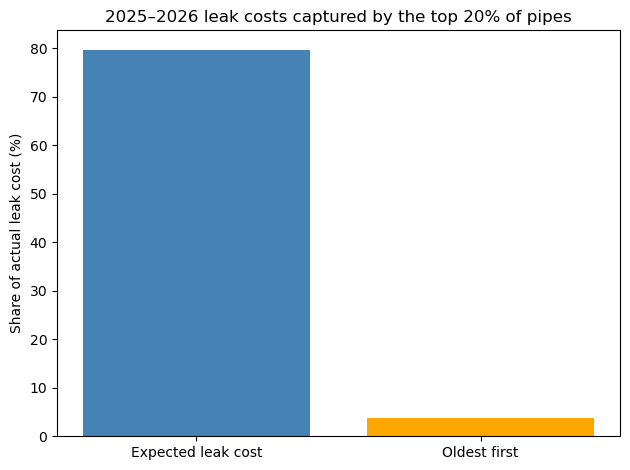

In [12]:
plt.bar(comparison["Method"], comparison["Share of actual leak cost (%)"],
        color=["steelblue", "orange"])
plt.ylabel("Share of actual leak cost (%)")
plt.title("2025–2026 leak costs captured by the top 20% of pipes")
plt.tight_layout()
plt.show()

A higher bar means the selected pipes accounted for more of the later repair costs. It does not mean those costs could all have been avoided within the replacement budget. Compare predicted and actual total costs too: a useful ranking can still predict the dollar amount poorly. Missing ages are put last in the oldest-first ranking.

## 5. Make the final ranking for 2027
Now use all the historical years, 2019–2026. Remove pipes already repaired and score the remaining pipes for one year.

Known iron pipes must be covered by the final replacement plan. Copper and brass are optional targets. Unknown materials need review; I flag them for conservative coverage rather than claiming they are definitely iron.

In [13]:
group_risk, overall_rate, overall_cost = calculate_group_risk("2027-01-01")

not_polyurethane = pipe_data["Material"] != "polyurethane"
not_repaired = pipe_data["Date"].isna()
remaining_pipes = pipe_data[not_polyurethane & not_repaired].copy()
remaining_pipes = remaining_pipes.drop(columns=["Date", "Cost"])
remaining_pipes = remaining_pipes.merge(group_risk, on=["Material", "Surface"], how="left")

remaining_pipes["annual_leak_rate"] = remaining_pipes["annual_leak_rate"].fillna(overall_rate)
remaining_pipes["average_leak_cost"] = remaining_pipes["average_leak_cost"].fillna(overall_cost)
remaining_pipes["leak_probability"] = 1 - np.exp(-remaining_pipes["annual_leak_rate"])
remaining_pipes["priority_score"] = remaining_pipes["leak_probability"] * remaining_pipes["average_leak_cost"]

iron_materials = ["cast iron", "wrought iron", "gray iron"]
remaining_pipes["must_replace_iron"] = remaining_pipes["Material"].isin(iron_materials)
remaining_pipes["unknown_material"] = remaining_pipes["Material"] == "unknown"

priority_list = remaining_pipes.sort_values(
    ["priority_score", "Pipe ID"], ascending=[False, True]
).reset_index(drop=True)
priority_list.insert(0, "Rank", range(1, len(priority_list) + 1))

print("Remaining known iron pipes:", priority_list["must_replace_iron"].sum())
print("Unknown material pipes:", priority_list["unknown_material"].sum())
priority_list[["Rank", "Pipe ID", "Material", "Surface", "leak_probability",
               "average_leak_cost", "priority_score", "must_replace_iron"]].head(20)

Remaining known iron pipes: 26237
Unknown material pipes: 8


,Rank,Pipe ID,Material,Surface,leak_probability,average_leak_cost,priority_score,must_replace_iron
0,1,P12143,brass,road,0.143148,285276.703333,40836.730086,False
1,2,P20916,brass,road,0.143148,285276.703333,40836.730086,False
2,3,P32226,brass,road,0.143148,285276.703333,40836.730086,False
3,4,P32228,brass,road,0.143148,285276.703333,40836.730086,False
4,5,P32237,brass,road,0.143148,285276.703333,40836.730086,False
5,6,P35280,brass,road,0.143148,285276.703333,40836.730086,False
6,7,P35570,brass,road,0.143148,285276.703333,40836.730086,False
7,8,P35608,brass,road,0.143148,285276.703333,40836.730086,False
8,9,P35614,brass,road,0.143148,285276.703333,40836.730086,False
9,10,P38280,brass,road,0.143148,285276.703333,40836.730086,False


## 6. Save the results
The priority list is an input to the team's planning work. It is **not** the assignment submission CSV, which needs circle centres and radii.

In [14]:
priority_list.to_csv(output_folder / "pipe_priority_2027.csv", index=False)
comparison.to_csv(output_folder / "priority_validation.csv", index=False)
print("Results saved in:", output_folder)

Results saved in: /Users/wendy/Desktop/STAT 440/STAT440_GP1/data/processed


## What this analysis can and cannot tell us
This provides a simple replacement-order baseline and a comparison with oldest-first. It does not choose excavation circles, calculate a feasible schedule, or demonstrate savings.

Important limits:
- Material and surface groups can contain very different pipes. This version does not model age, length, location, or year effects.
- Rare, very expensive leaks strongly affect average costs. Small groups and groups without leaks are uncertain; zero observed leaks does not prove zero future risk.
- The constant-rate assumption may not hold over future years. Do not treat these scores as a 25-year forecast.
- Every remaining iron pipe still needs coverage regardless of its priority score. Circle costs and annual funding must be checked separately.
- If you change settings based on the test results, that period is no longer an untouched final test.